# Bluebikes: three-minute review demo

DADS5250 / Group 8. **Recording and upload are not completed.** Human/team review and TA confirmation remain pending. This view replays genuine saved OpenAI calls with hash validation and makes **zero new API calls**. Fixtures are not shown as model outputs. Run the submission Notebook first to regenerate analysis tables.

## 1. The problem and ordinary backtest

Train/select on 2024-2025; freeze the plan; evaluate against the January-September 2026 observed-trip inventory proxy. Costs and shortages below cover **the same nine months**. The proxy is neither lost trips nor measured operator work; archive gaps and current-station matching limitations remain. [Full audit](bluebikes_submission.ipynb), [English script](../docs/DEMO_SCRIPT.md).


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'bluebikes').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
pd.set_option('display.max_colwidth', 140)
from bluebikes.events import run_extraction, load_documents
from bluebikes.event_validation import run_additional_evaluation
original = run_extraction('recorded', root=ROOT)
assert original['live_llm_verified'] and original['api_calls'] == 0
assert original['evaluation']['correct_fields'] == 19
assert original['evaluation']['total_fields'] == 20
periods = pd.read_csv(ROOT / 'results/scenario_period_comparison.csv')
ordinary = periods[(periods.period_months == 9) & periods.scenario.isin(['initial_crews_factor1','proposal_no_event_factor1'])]
columns = ['scenario','period','crew_cash_cost_in_period','uncovered_handling_actions','peak_total_crews_in_period']
display(ordinary[columns].round(2))
print('Ordinary frozen-plan backtest. Historical original API calls:', original['recorded_api_calls'], '; new API calls:', original['api_calls'])

,scenario,period,crew_cash_cost_in_period,uncovered_handling_actions,peak_total_crews_in_period
1,initial_crews_factor1,2026-01 through 2026-09,756000.0,326680.86,14
3,proposal_no_event_factor1,2026-01 through 2026-09,1342800.0,48126.86,32


Ordinary frozen-plan backtest. Historical original API calls: 4 ; new API calls: 0


## Shared flow and visible roles

Read the cached diagram from historical trip/station inputs to the frozen forecast, and from official event text through an OpenAI API call, prompt engineering and structured JSON extraction. Python validates; a human confirms; an explicit user demand assumption and Apply action gate the Python crew optimizer. Held-out 2026 January-September trips feed backtesting only, with no return path to training. The app and README use this same generated SVG from `docs/diagrams/bluebikes_flow.mmd`, without a Mermaid CDN or runtime Node requirement.


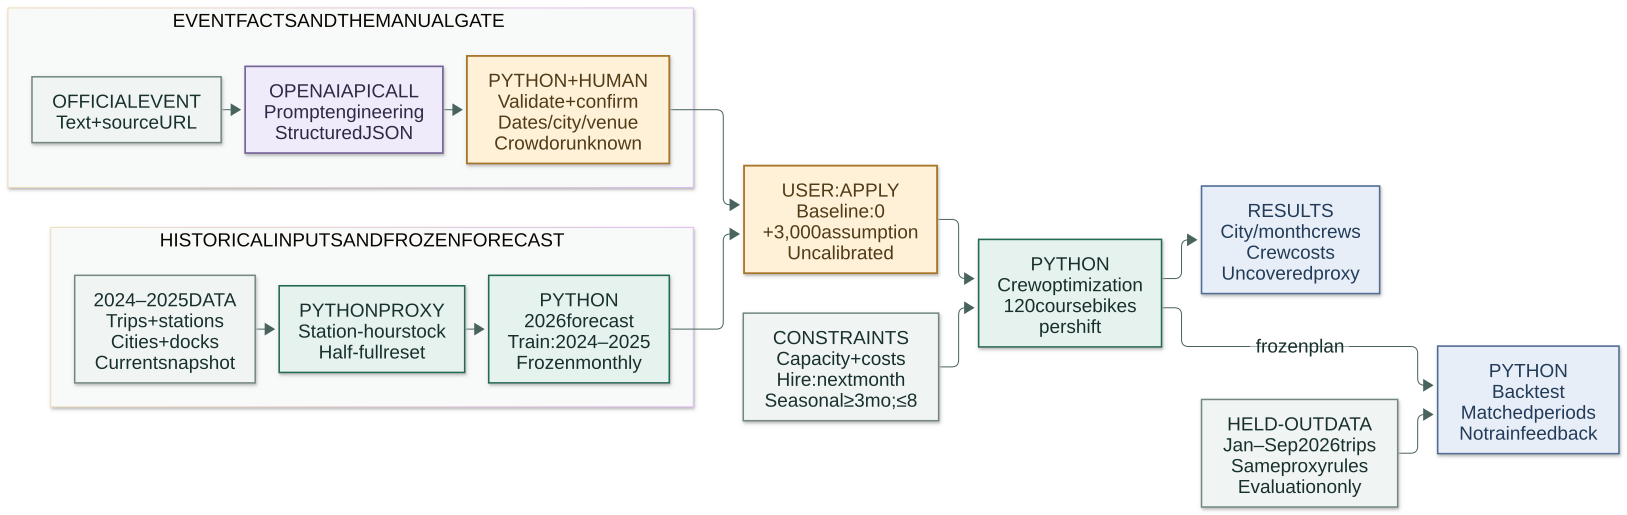

In [2]:
from IPython.display import SVG
architecture_diagram = ROOT / 'docs/diagrams/bluebikes_flow.svg'
assert architecture_diagram.exists(), 'Regenerate the canonical diagram with node scripts/render_architecture.mjs'
display(SVG(filename=str(architecture_diagram)))

## 2. Actual announcement to actual LLM extraction

The input is a preserved real-source excerpt. The output below is a **recorded actual OpenAI response**, not the fixture. The model assigns the route to its named Boston endpoint; that city allocation is an explicit convention needing review. Crowd is null because the original announcement's 30,000 athletes are not a spectator estimate.


In [3]:
doc = load_documents(ROOT)[0]
event = original['events'][0]
print('Source:', doc['source_url'])
print('INPUT EXCERPT:', doc['source_text'])
print('ACTUAL STRUCTURED OUTPUT:')
print(json.dumps(event, indent=2))
print('API provenance:')
display(pd.DataFrame(original['calls'])[['source_id','model','executed_at_utc','response_status']].head(1))

Source: https://www.baa.org/news/media-resources-schedule-of-events-for-the-130th-boston-marathon-presented-by-bank-of-america/
INPUT EXCERPT: 130th Boston Marathon ... Monday, April 20, 2026 ... Hopkinton to Boston ... A field of 30,000 athletes
ACTUAL STRUCTURED OUTPUT:
{
  "event_name": "130th Boston Marathon",
  "start_date": "2026-04-20",
  "end_date": "2026-04-20",
  "location": "Hopkinton to Boston",
  "city": "Boston",
  "expected_crowd_size": null,
  "source_url": "https://www.baa.org/news/media-resources-schedule-of-events-for-the-130th-boston-marathon-presented-by-bank-of-america/",
  "evidence_text": "130th Boston Marathon ... Monday, April 20, 2026 ... Hopkinton to Boston ... A field of 30,000 athletes",
  "missing_info": [
    "expected_crowd_size"
  ],
  "ambiguities": [
    "location is a route from Hopkinton to Boston, city is set to Boston as endpoint but event spans multiple municipalities"
  ]
}
API provenance:


,source_id,model,executed_at_utc,response_status
0,boston_marathon_2026,gpt-4.1-mini-2025-04-14,2026-10-26T23:35:00.438740+00:00,completed


## 3. City and month to a conditional crew decision

**Retrospective scenario: +3,000 handling actions is an uncalibrated assumption, not an extracted fact or evidence of improved forecasting.** Only the original Marathon record is used for this focused scenario. The existing planner adds the increment to Boston/April and resolves annual staffing constraints. April payroll and April shortage share a one-month horizon; annual hiring/contracts can change other months too. The ordinary backtest remains separate.


,event_name,start_date,city,year,month,event_increment_handling_actions,source_url
0,130th Boston Marathon,2026-04-20,Boston,2026,4,3000.0,https://www.baa.org/news/media-resources-schedule-of-events-for-the-130th-boston-marathon-presented-by-bank-of-america/


,city,month,demand_bikes_base,demand_bikes_scenario,full_time_base,full_time_scenario,seasonal_base,seasonal_scenario,crew_cost_base,crew_cost_scenario,unmet_bikes_base,unmet_bikes_scenario
15,Boston,4,36721.19,39721.19,12,13,0,0,72000.0,78000.0,0.0,0.0


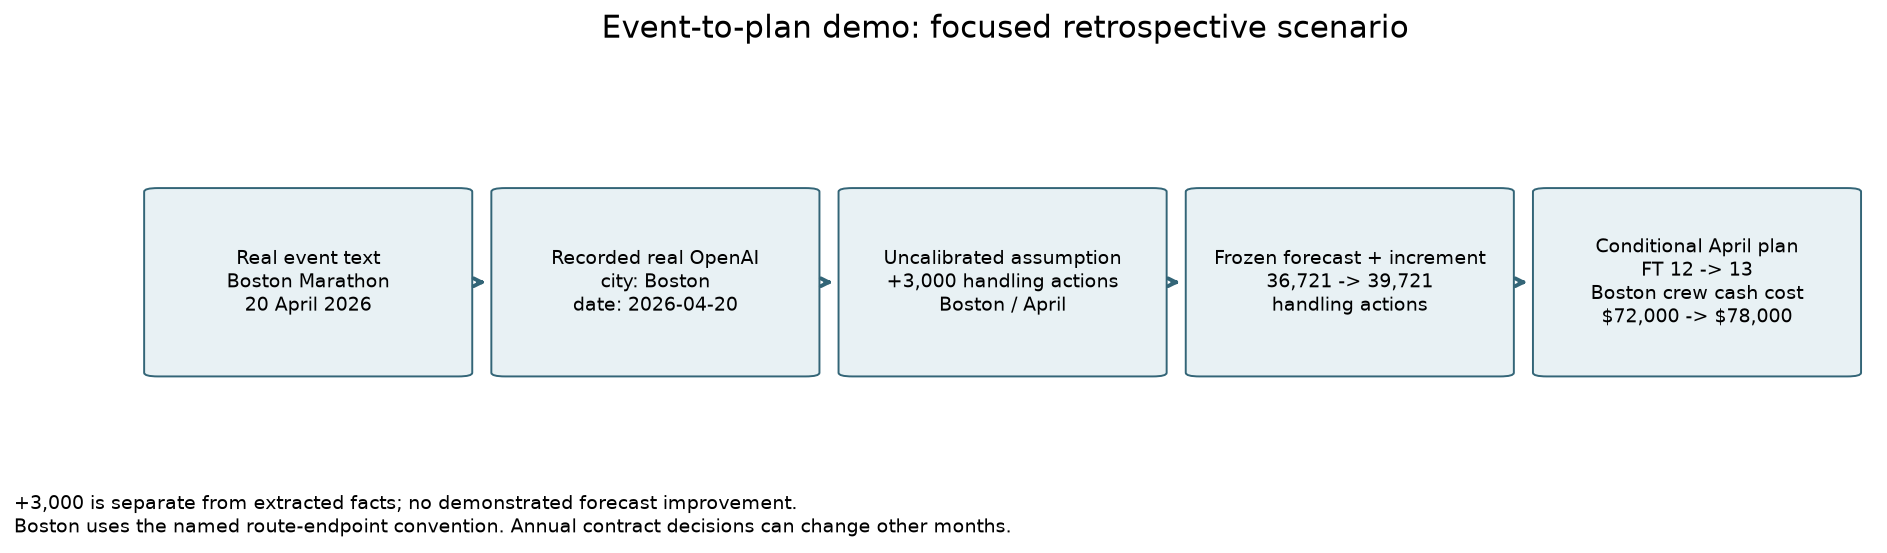

Whole-plan nine-month evaluation: retrospective only; no causal/forecast-improvement claim


,scenario,period,crew_cash_cost_in_period,uncovered_handling_actions,peak_total_crews_in_period
3,proposal_no_event_factor1,2026-01 through 2026-09,1342800.0,48126.86,32
5,focused_marathon_plus3000_factor1,2026-01 through 2026-09,1339800.0,45740.43,32


In [4]:
inputs = pd.read_csv(ROOT / 'results/focused_event_city_month_inputs.csv')
display(inputs[['event_name','start_date','city','year','month','event_increment_handling_actions','source_url']])
chain = pd.read_csv(ROOT / 'results/focused_event_chain.csv')
april = chain[(chain.city == 'Boston') & (chain.month == 4)]
display(april[['city','month','demand_bikes_base','demand_bikes_scenario','full_time_base','full_time_scenario','seasonal_base','seasonal_scenario','crew_cost_base','crew_cost_scenario','unmet_bikes_base','unmet_bikes_scenario']].round(2))
assert april.event_increment_handling_actions.iloc[0] == 3000
assert april.full_time_scenario.iloc[0] > april.full_time_base.iloc[0]
display(Image(filename=str(ROOT / 'results/figures/event_demo_chain.png')))
print('Whole-plan nine-month evaluation: retrospective only; no causal/forecast-improvement claim')
display(periods[(periods.period_months == 9) & periods.scenario.isin(['proposal_no_event_factor1','focused_marathon_plus3000_factor1'])][columns].round(2))

## 4. Hand count: eight station actions versus four relocations

**Synthetic, hand-checkable example:** both stations have four docks and start with two bikes. Four A-to-B customer trips cause two supplies at A and two collections at B. Resetting both stations to half full adds two supplies and two collections: **8 handling actions**. Pairing pickup and delivery gives **4 relocation tasks**, possibly reusing physical bikes. A reverse-hour example has zero daily customer net but still requires action; the unbalanced-depot example cannot automatically be halved.

**120 bikes/shift remains unchanged.** The two interpretations change the conversion between course-bike units and proxy actions, not the course number. In January, 120 * 6 * 31/7 = 3,188.57 course-bike units per crew. No feasible van route, depot stock or within-hour order is established.


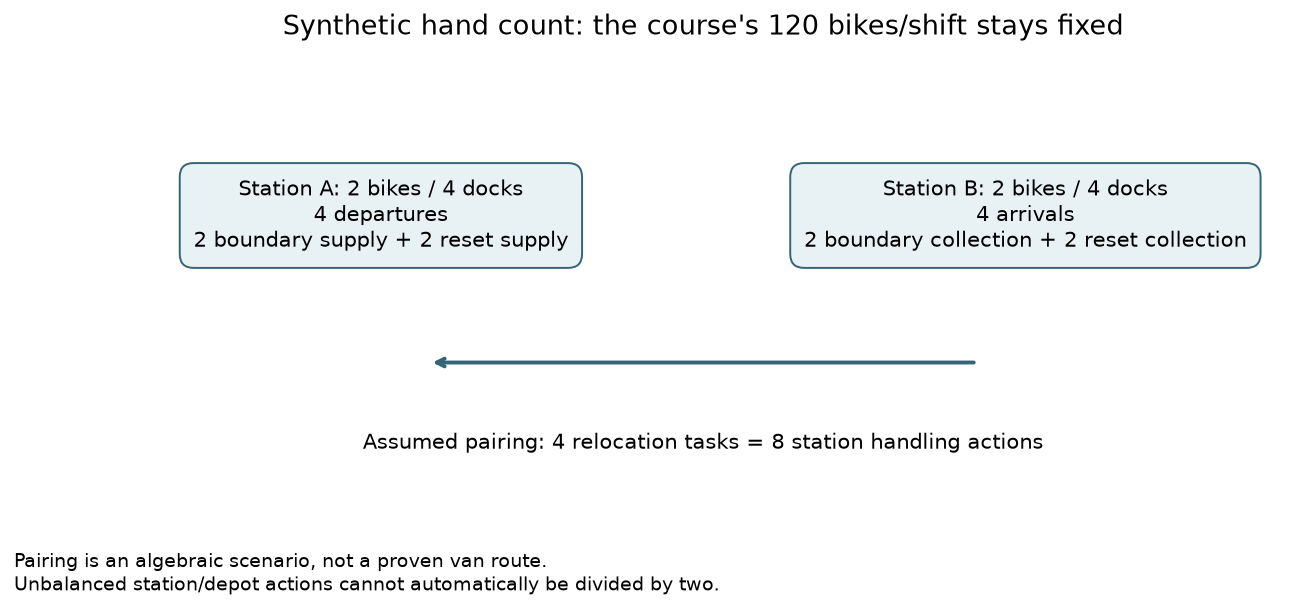

,case,description,departures,arrivals,within_day_supply,within_day_collection,reset_supply,reset_collection,handling_actions,assumed_paired_relocations,pairing_assumption
0,synthetic_one_way,Four customer trips A to B in one hour,4,4,2,2,2,2,8,4.0,"Two B-to-A pickups/deliveries during the day, plus two B-to-A resets; algebraic pairing only"
1,synthetic_return_hour,"Four A-to-B trips, then four B-to-A trips in the next hour",8,8,2,2,2,2,8,4.0,"Two B-to-A pickups/deliveries during the day, plus two A-to-B resets; algebraic pairing only"
2,synthetic_external_depot,Four departures from A; arrivals occur outside the two-station example,4,0,2,0,2,0,4,NaN,Four local deliveries from an external depot; its pickup endpoints are outside the example


,month,calendar_days,course_bikes_per_shift,shifts_per_week,average_crew_shifts,endpoint_capacity_factor,monthly_course_bike_capacity,monthly_handling_capacity,assumption
0,2026-01,31,120,6,26.57,1,3188.57,3188.57,Course bike means one handling action
1,2026-01,31,120,6,26.57,2,3188.57,6377.14,Course bike means one completed relocation with two included endpoints


In [5]:
display(Image(filename=str(ROOT / 'results/figures/handling_unit_demo.png')))
display(pd.read_csv(ROOT / 'results/unit_example_case_summary.csv'))
display(pd.read_csv(ROOT / 'results/unit_example_monthly_capacity.csv').round(2))

## 5. What that unit assumption changes

Both rows use the **same January-September 2026 horizon** and report shortages in handling actions. Factor one maps one action to one course-bike unit; factor two assumes paired pickup/delivery and maps two actions to one course-bike unit. Replanning uses only frozen 2024-2025 forecasts; 2026 observations are evaluation only. The assumed penalty per uncovered handling action is held fixed, and **120 bikes/shift is unchanged**. These are conditional model results, not measured productivity.

The older frozen-crew sensitivity changes shortages while leaving crew counts/costs unchanged. This table instead reruns staffing optimization under the alternate conversion. Annual comparisons and 2027 seasonal obligations are in the full audit.


In [6]:
units = pd.read_csv(ROOT / 'results/unit_interpretation_comparison.csv')
units = units[(units.period_months == 9) & units.scenario.isin(['proposal_no_event_factor1','replanned_no_event_factor2'])]
assert (units.course_bikes_per_shift == 120).all()
display(units[['scenario','period','handling_actions_per_course_bike','course_bikes_per_shift','peak_total_crews_in_period','full_time_crew_months_in_period','seasonal_crew_months_in_period','crew_cash_cost_in_period','uncovered_handling_actions']].round(2))

,scenario,period,handling_actions_per_course_bike,course_bikes_per_shift,peak_total_crews_in_period,full_time_crew_months_in_period,seasonal_crew_months_in_period,crew_cash_cost_in_period,uncovered_handling_actions
3,proposal_no_event_factor1,2026-01 through 2026-09,1.0,120.0,32,190,26,1342800.0,48126.86
7,replanned_no_event_factor2,2026-01 through 2026-09,2.0,120.0,18,118,14,830700.0,30640.14


## 6. Separate audience challenge: failure stays visible

The original four calls retain **19/20 = 95%** against frozen, **AI-authored provisional labels**. The three new actual calls score **11/15 = 73.33%** separately; neither score is a human-gold accuracy estimate. Two positive spectator sources describe the **same** regatta (correlated, not two independent events). Both numeric spectator counts match; the participant-only case incorrectly outputs 30,000 spectators and unsupported dates. Source quantity qualifiers are preserved in annotations but missing from the model's ambiguity explanation.

These added records are **evaluation only** and never enter the demand adjustment. The table juxtaposes input, provisional reference, actual model output and a blank human judgment. Full unabridged JSON/evidence and editable judgment columns: [review CSV](../results/event_extraction_additional_review.csv); [review notes](../docs/human_review_additional.md). No row is human confirmed.


In [7]:
additional = run_additional_evaluation('recorded', root=ROOT)
assert additional['live_llm_verified'] and additional['api_calls'] == 0
metrics = additional['evaluation']
assert (metrics['correct_fields'], metrics['total_fields']) == (11, 15)
print('Separate actual-call evaluation:', metrics['correct_fields'], '/', metrics['total_fields'])
print('Recorded additional calls:', additional['recorded_api_calls'], '; new API calls:', additional['api_calls'])
review = pd.read_csv(ROOT / 'results/event_extraction_additional_review.csv', keep_default_na=False)
def concise(raw):
    obj = json.loads(raw)
    return json.dumps({k: obj[k] for k in ['start_date','end_date','location','city','expected_crowd_size','ambiguities']}, indent=2)
view = pd.DataFrame({'Input excerpt + source':review.input_excerpt + '\n' + review.source_url,
                     'Provisional reference (AI draft)':review.reference_json.map(concise),
                     'Actual LLM output':review.llm_output_json.map(concise),
                     'Human judgment':review.human_judgment,
                     'Review status':review.human_review_status})
display(view.style.set_properties(**{'white-space':'pre-wrap','text-align':'left','vertical-align':'top','min-width':'180px','max-width':'350px'}).hide(axis='index'))
display(pd.DataFrame(metrics['disagreements']))
print('All additional cases: evaluation only. Human review PENDING. Video NOT RECORDED / NOT UPLOADED.')

Separate actual-call evaluation: 11 / 15
Recorded additional calls: 3 ; new API calls: 0


Input excerpt + source,Provisional reference (AI draft),Actual LLM output,Human judgment,Review status
"October 15, 2026 ... October 16, 17, and 18 ... for one weekend each October, more than 300,000 spectators ... Charles River ... over 12,000 rowers https://www.bu.edu/articles/2026/rowers-prepare-head-of-charles-regatta/","{ ""start_date"": ""2026-10-16"", ""end_date"": ""2026-10-18"", ""location"": ""Charles River"", ""city"": null, ""expected_crowd_size"": 300000, ""ambiguities"": [ ""The crowd value is a lower-bound threshold: more than 300,000, not exactly 300,000."", ""The audience statement describes the recurring event in a 2026 preview, not a measured 2026 attendance count."", ""The source excerpt does not state a municipality; no city is inferred from the event or river name."" ] }","{ ""start_date"": ""2026-10-16"", ""end_date"": ""2026-10-18"", ""location"": ""Charles River"", ""city"": null, ""expected_crowd_size"": 300000, ""ambiguities"": [ ""Charles River spans multiple municipalities, city not specified"" ] }",,PENDING
"October 16-18, 2026 ... Charles River between Boston and Cambridge ... approximately 325,000 unique spectators, 11,500 competitors, and 2,400 volunteers. https://www.avive.life/news/head-of-the-charles-regatta","{ ""start_date"": ""2026-10-16"", ""end_date"": ""2026-10-18"", ""location"": ""Charles River between Boston and Cambridge"", ""city"": null, ""expected_crowd_size"": 325000, ""ambiguities"": [ ""The source names both Boston and Cambridge without allocating the audience to a single city."", ""The crowd value is approximately 325,000 unique spectators, not an exact count."", ""Competitors and volunteers are separate roles and are not added to the expected audience."" ] }","{ ""start_date"": ""2026-10-16"", ""end_date"": ""2026-10-18"", ""location"": ""Charles River between Boston and Cambridge"", ""city"": null, ""expected_crowd_size"": 325000, ""ambiguities"": [ ""city is ambiguous because the event spans between Boston and Cambridge"" ] }",,PENDING
"The 2026 Boston Marathon Spectator Guide ... Main Street and see 30,000 participants depart historic Hopkinton! https://www.baa.org/races/boston-marathon/info-for-spectators/","{ ""start_date"": null, ""end_date"": null, ""location"": ""Main Street"", ""city"": ""Hopkinton"", ""expected_crowd_size"": null, ""ambiguities"": [ ""30,000 describes participants, not spectators; the spectator count must remain null."", ""A year is stated but no event day is given in this excerpt; no calendar date is guessed."" ] }","{ ""start_date"": ""2026-04-21"", ""end_date"": ""2026-04-21"", ""location"": ""Main Street, Hopkinton"", ""city"": ""Hopkinton"", ""expected_crowd_size"": 30000, ""ambiguities"": [ ""The exact date of the 2026 Boston Marathon is not explicitly stated in the excerpt; the date 2026-04-21 is inferred from typical scheduling but not confirmed in the text."" ] }",,PENDING


,source_id,field,expected,predicted,exact_match
0,additional_baa_participants_only_2026,start_date,NaN,2026-04-21,False
1,additional_baa_participants_only_2026,end_date,NaN,2026-04-21,False
2,additional_baa_participants_only_2026,location,Main Street,"Main Street, Hopkinton",False
3,additional_baa_participants_only_2026,expected_crowd_size,NaN,30000,False


All additional cases: evaluation only. Human review PENDING. Video NOT RECORDED / NOT UPLOADED.


## Architecture and recording handoff

Use the shared Mermaid figure displayed above for architecture and presentation. The API call reaches OpenAI, the versioned prompt defines fields and unknowns, and structured output supports Python validation and human-confirmed planning input. Recorded-call hashes keep the demo reproducible; structural validation does not guarantee semantic correctness.

**Remaining:** human extraction/unit review, all-member contributions/review, TA confirmation, rehearse and record/upload the three-minute video, verify teaching-team access, and submit manually to Canvas. Do not mark submission complete until those requirements are met.


## Optional interactive local app — off by default

The cells above remain the reproducible recording view. Install the current `requirements.txt` before using this optional app. Keep `LAUNCH_LOCAL_APP = False` for execution/submission: no server starts and no live API call is made. Opt in by setting it to `True` below. The default port remains 7860; set `LOCAL_APP_PORT = 7872` for this polished revision's review, matching `python scripts/run_app.py --port 7872` and avoiding an older process on 7860. The app binds to **127.0.0.1**, with sharing and analytics disabled.

Start with the saved real input/output and results. A new model call happens only through **実APIで抽出 / Extract with OpenAI**. Review the editable fields and ambiguities, explain corrections in notes, click **Confirm reviewed values (this session only)**, then **計画に反映 / Apply to plan**. Review edits stay in the session. Source, reviewed event or assumption edits invalidate an applied scenario and require another apply; a source change requires replay/extraction and review again. The frozen original four calls/19-of-20 agreement and separate three-call/11-of-15 challenge are retained, with failures and human review still pending.

Keep +3,000 labelled **uncalibrated retrospective**, 120 course bikes/shift fixed during unit conversion, hiring decisions distinct from next-month active crews, and annual forecast/cost results separate from January-September observed-proxy/cost results. The app does not turn these assumptions into verified operating facts.

Stop a Notebook session with **`app.close()`** in a new cell, or restore the flag to `False` and rerun this cell. Stop the standalone process with **Ctrl+C**. Save the submission with the flag `False`. See `docs/verification-gradio.json` for separately recorded integration checks; inspect the evidence before recording a demo.


In [8]:
LAUNCH_LOCAL_APP = False
LOCAL_APP_PORT = 7860
if LAUNCH_LOCAL_APP:
    from bluebikes.app import launch_local
    if 'app' in globals() and app is not None:
        app.close()
    app = launch_local(ROOT, port=LOCAL_APP_PORT, inline=True, prevent_thread_lock=True)
else:
    if 'app' in globals() and app is not None:
        app.close()
        app = None
    print('Local app is OFF. Set LAUNCH_LOCAL_APP=True only for an interactive local session.')
# To stop an app you explicitly started, run app.close() in a new cell.
# Restore LAUNCH_LOCAL_APP=False before saving or executing the submitted Notebook.

Local app is OFF. Set LAUNCH_LOCAL_APP=True only for an interactive local session.
